In [1]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

/kaggle/input/weather-long-term-time-series-forecasting/cleaned_weather.csv


In [2]:
import pandas as pd
import numpy as np
import tensorflow as tf

In [3]:
df = pd.read_csv('/kaggle/input/weather-long-term-time-series-forecasting/cleaned_weather.csv',index_col='date')

In [4]:
df.head(5)

,p,T,Tpot,Tdew,rh,VPmax,VPact,VPdef,sh,H2OC,rho,wv,max. wv,wd,rain,raining,SWDR,PAR,max. PAR,Tlog
date,,,,,,,,,,,,,,,,,,,,
2020-01-01 00:10:00,1008.89,0.71,273.18,-1.33,86.1,6.43,5.54,0.89,3.42,5.49,1280.62,1.02,1.60,224.3,0.0,0.0,0.0,0.0,0.0,11.45
2020-01-01 00:20:00,1008.76,0.75,273.22,-1.44,85.2,6.45,5.49,0.95,3.39,5.45,1280.33,0.43,0.84,206.8,0.0,0.0,0.0,0.0,0.0,11.51
2020-01-01 00:30:00,1008.66,0.73,273.21,-1.48,85.1,6.44,5.48,0.96,3.39,5.43,1280.29,0.61,1.48,197.1,0.0,0.0,0.0,0.0,0.0,11.60
2020-01-01 00:40:00,1008.64,0.37,272.86,-1.64,86.3,6.27,5.41,0.86,3.35,5.37,1281.97,1.11,1.48,206.4,0.0,0.0,0.0,0.0,0.0,11.70
2020-01-01 00:50:00,1008.61,0.33,272.82,-1.50,87.4,6.26,5.47,0.79,3.38,5.42,1282.08,0.49,1.40,209.6,0.0,0.0,0.0,0.0,0.0,11.81


In [5]:
df.shape

(52696, 20)

In [6]:
df.columns

Index(['p', 'T', 'Tpot', 'Tdew', 'rh', 'VPmax', 'VPact', 'VPdef', 'sh', 'H2OC',
       'rho', 'wv', 'max. wv', 'wd', 'rain', 'raining', 'SWDR', 'PAR',
       'max. PAR', 'Tlog'],
      dtype='object')

<Axes: xlabel='date'>

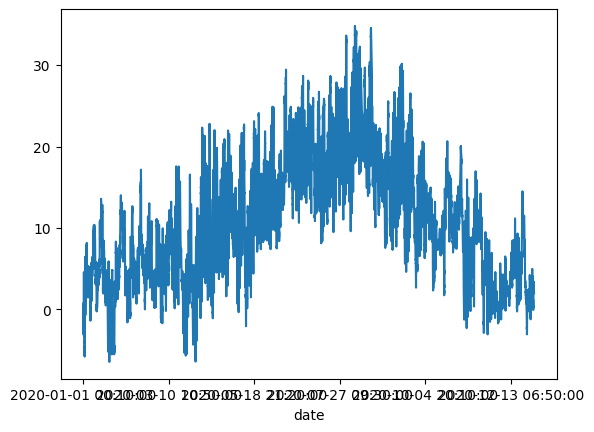

In [7]:
temp=df['T']
temp.plot()

In [8]:
def df_to_X_y(df, window_size):
    X, y = [], []
    df_as_np = df.to_numpy()
    for i in range(len(df_as_np) - window_size):
        row = df_as_np[i:i + window_size]  # Collect a window of size `window_size`
        X.append(row)
        label = df_as_np[i + window_size]  # Label corresponds to the next value
        y.append(label)
    return np.array(X), np.array(y)


In [9]:
WINDOW_SIZE = 5
X, y = df_to_X_y(temp, WINDOW_SIZE)
X.shape, y.shape

((52691, 5), (52691,))

In [10]:
X

array([[0.71, 0.75, 0.73, 0.37, 0.33],
       [0.75, 0.73, 0.37, 0.33, 0.34],
       [0.73, 0.37, 0.33, 0.34, 0.19],
       ...,
       [2.35, 2.32, 2.27, 2.28, 2.13],
       [2.32, 2.27, 2.28, 2.13, 1.99],
       [2.27, 2.28, 2.13, 1.99, 2.07]])

In [11]:
y

array([0.34, 0.19, 0.03, ..., 1.99, 2.07, 2.01])

In [12]:
X_train, y_train = X[:40000], y[:40000]
X_val, y_val = X[40000:45000], y[40000:45000]
X_test, y_test = X[45000:], y[45000:]

In [13]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import *
from tensorflow.keras.callbacks import ModelCheckpoint
from tensorflow.keras.losses import MeanSquaredError
from tensorflow.keras.metrics import RootMeanSquaredError
from tensorflow.keras.optimizers import Adam

In [14]:
X_train.shape, y_train.shape

((40000, 5), (40000,))

In [15]:
model1 = Sequential()
model1.add(InputLayer((5,1)))
model1.add(LSTM(64))
model1.add(Dense(8, 'relu'))
model1.add(Dense(1, 'linear'))

model1.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                          │ (None, 64)                  │          16,896 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense (Dense)                        │ (None, 8)                   │             520 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 1)                   │               9 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 17,425 (68.07 KB)

 Trainable params: 17,425 (68.07 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
# Save the best model in .keras format
cp = ModelCheckpoint('/kaggle/working/best_model.keras', save_best_only=True)
model1.compile(loss=MeanSquaredError(), optimizer=Adam(learning_rate=0.0001), metrics = [RootMeanSquaredError()])

In [17]:
model1.fit(X_train, y_train, validation_data=(X_val, y_val), epochs=10, callbacks=[cp])

Epoch 1/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 7s 4ms/step - loss: 115.7578 - root_mean_squared_error: 10.5425 - val_loss: 0.1279 - val_root_mean_squared_error: 0.3577
Epoch 2/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 2.5344 - root_mean_squared_error: 1.5815 - val_loss: 0.0828 - val_root_mean_squared_error: 0.2877
Epoch 3/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.6411 - root_mean_squared_error: 0.7994 - val_loss: 0.0545 - val_root_mean_squared_error: 0.2334
Epoch 4/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.2845 - root_mean_squared_error: 0.5322 - val_loss: 0.0497 - val_root_mean_squared_error: 0.2230
Epoch 5/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 5s 4ms/step - loss: 0.1442 - root_mean_squared_error: 0.3794 - val_loss: 0.0417 - val_root_mean_squared_error: 0.2042
Epoch 6/10
1250/1250 ━━━━━━━━━━━━━━━━━━━━ 4s 4ms/step - loss: 0.0899 - root_mean_squared_error: 0.2996 - val_loss: 0.0348 - val_root_mean_squared_error: 0.1866
Epoch 7/10
1250/1250 ━━━━━━━━━━━━━━━━

In [18]:
from tensorflow.keras.models import load_model


In [19]:


model1 = load_model('/kaggle/working/best_model.keras')


In [20]:
train_predictions = model1.predict(X_train).flatten()
train_results = pd.DataFrame(data={'Train Predictions':train_predictions, 'Actuals':y_train})
train_results

1250/1250 ━━━━━━━━━━━━━━━━━━━━ 3s 2ms/step


,Train Predictions,Actuals
0,0.333697,0.34
1,0.330603,0.19
2,0.242034,0.03
3,0.084073,0.11
4,0.109191,0.22
...,...,...
39995,12.262368,12.23
39996,12.202822,12.14
39997,12.052973,12.10
39998,12.037598,12.02


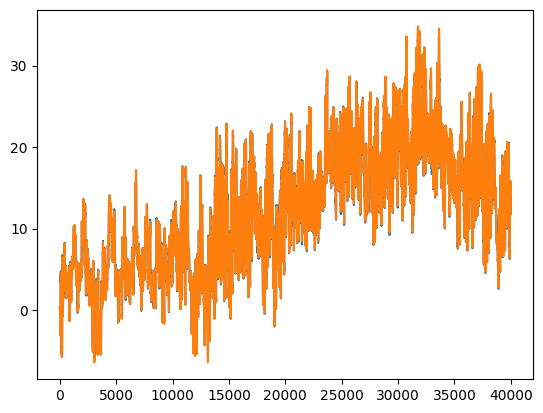

In [21]:
import matplotlib.pyplot as plt

plt.plot(train_results['Train Predictions'])
plt.plot(train_results['Actuals'])


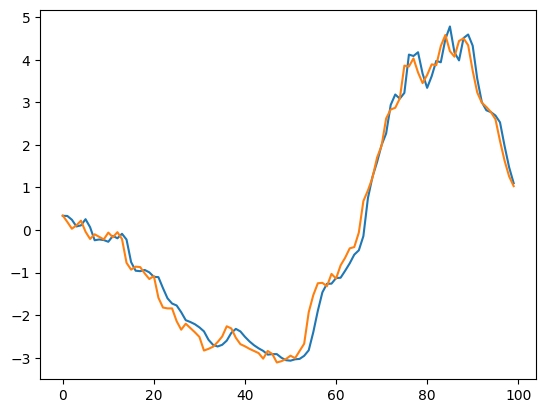

In [22]:
plt.plot(train_results['Train Predictions'][:100])
plt.plot(train_results['Actuals'][:100])


In [23]:
val_predictions = model1.predict(X_val).flatten()
val_results = pd.DataFrame(data={'Val Predictions':val_predictions, 'Actuals':y_val})
val_results

157/157 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step


,Val Predictions,Actuals
0,11.496532,11.47
1,11.289225,11.25
2,11.076960,10.94
3,10.719994,10.83
4,10.713364,10.70
...,...,...
4995,12.130916,12.13
4996,12.245051,12.28
4997,12.343237,12.57
4998,12.705544,13.13


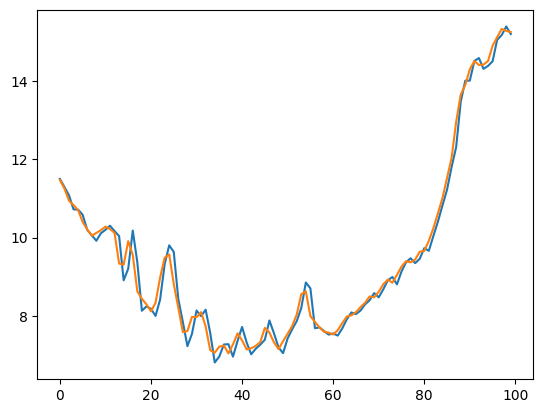

In [24]:
plt.plot(val_results['Val Predictions'][:100])
plt.plot(val_results['Actuals'][:100])

In [25]:
test_predictions = model1.predict(X_test).flatten()
test_results = pd.DataFrame(data={'Test Predictions':test_predictions, 'Actuals':y_test})
test_results

241/241 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step


,Test Predictions,Actuals
0,13.743109,13.69
1,13.733429,13.35
2,13.134083,13.12
3,12.957167,13.01
4,12.893234,13.31
...,...,...
7686,2.283610,2.28
7687,2.279697,2.13
7688,2.117262,1.99
7689,1.950887,2.07


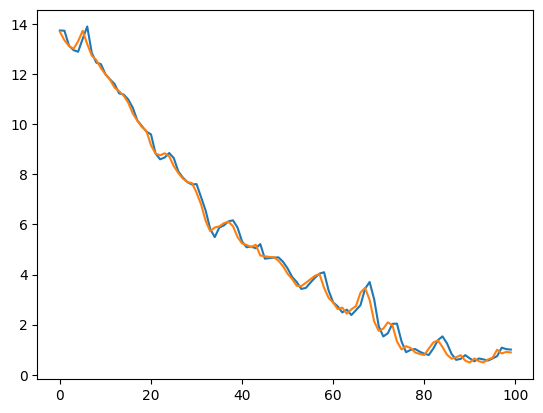

In [26]:
plt.plot(test_results['Test Predictions'][:100])
plt.plot(test_results['Actuals'][:100])